<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/00_data_acquisition_and_dictionary.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 00 · Data acquisition, preparation and data dictionary

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

This notebook collects all the data used in Chapter 3. It downloads every series from the organisation that
publishes it, checks it, builds the covariates, and saves a frozen copy, the *snapshot*, in `input_timeseries/`.
Every later notebook reads from that snapshot: six datasets, a manifest file with checksums, and a data
dictionary that explains every column.

Why so much care over data for models that are used zero-shot? Because a forecast can only be judged against data
we trust. Pretrained models have seen large public collections of time series, so we use fresh data taken straight
from the original publishers and record exactly which version (the *vintage*) we used. We also sort every
covariate by *when its value becomes known*. That simple label is what stops a covariate experiment from quietly
using information from the future.

| ID | Dataset | Structure | Grain | Size |
|---|---|---|---|---|
| D1 | Central England Temperature (HadCET), daily mean | univariate (U) | daily | last 10,000 days |
| D2 | D1 + seasonal, wavelet and climate-index covariates | univariate + covariates (U+X) | daily | 10,000 days × 15 columns |
| D3 | Five base-metal prices (copper, aluminium, nickel, zinc, lead) | multivariate (MV) | monthly | Jan 1982 onwards |
| D4 | D3 + global activity, US dollar, US real rate | multivariate + covariates (MV+X) | monthly | same months as D3 |
| B1 | WTI crude oil spot price (bonus) | U | trading day | last 10,000 days |
| B2 | US Treasury yields, 3 months to 10 years (bonus) | MV | trading day | last 10,000 days |

**What you will learn**

- how to download a reproducible snapshot from the original sources and record checksums for it
- how to check a daily climate record and a set of monthly prices before modelling
- three kinds of covariates and the maths behind them: Fourier terms, day length from astronomy, and wavelet
  bands that use only the past
- why it matters more to know *when* a covariate is available (in advance, or only up to today) than what it is
  called
- how to write a data dictionary that a reader, or a later notebook, can rely on

| Environment and compute | |
|---|---|
| Python | 3.12 or 3.13 (Google Colab runs 3.13) |
| Packages | [`requirements-dataprep.txt`](requirements-dataprep.txt) (pinned versions); on Colab the setup cell adds the few that Colab lacks ([`requirements-colab.txt`](requirements-colab.txt)) |
| Hardware | CPU only (Colab free tier is enough) |
| Network | yes: downloads about 6 MB from FRED, the Met Office, NOAA CPC and the World Bank |
| Run time | under 1 minute on 4 CPU cores (Colab's free tier has 2: allow up to twice as long) |
| Peak memory | 0.2 GB (kernel peak) |

**How to run this notebook**

- **Google Colab:** choose *Runtime > Run all*. The first code cell fetches this chapter's folder and installs the
  packages Colab does not have (about a minute). If it says it is restarting the session, wait, then choose
  *Runtime > Run all* again. To use your own copy on Google Drive, set `DRIVE_COPY` in that cell to the folder's path.
- **Your own computer (Cursor, VS Code or Jupyter):** create an environment with
  `uv venv .venv-dataprep -p 3.12 && uv pip install -p .venv-dataprep -r requirements-dataprep.txt` (or
  `python -m venv .venv-dataprep` and `pip install -r ...`), open this folder, choose that environment's kernel and run
  all cells.

> **You do not need to run this notebook to use the others.** The snapshot built for the book is already in
> `input_timeseries/`. Running this notebook again downloads today's data into `data/raw/`, writes the new
> datasets to `data/rebuild/input_timeseries/` and, at the end, compares them with the frozen snapshot, so you can
> see how much the publishers have revised their data. Set `OVERWRITE_SNAPSHOT = True` only if you want to
> replace the book's snapshot (the numbers quoted in the text of Notebooks 01 to 04 will then no longer match).
> If your network blocks one of the sites, download the files by hand into `data/raw/` with the names printed
> below and set `USE_EXISTING_RAW = True`.

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install the packages Colab lacks)
import os
import sys
from pathlib import Path

CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
DRIVE_COPY = ""   # Colab only, optional: path of your own copy of this folder on Google Drive
IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:
    import importlib.metadata as md
    import shutil

    BOOK = Path("/content/book")

    def chapter_dir():
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):   # copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    if chapter_dir() is None and not DRIVE_COPY:      # 1) clone the book's repository
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                         # 2) not on GitHub (yet): copy it from Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if not DRIVE_COPY or not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"{CHAPTER} is not on GitHub or in your Google Drive. Set DRIVE_COPY to its path.")
        shutil.rmtree(BOOK, ignore_errors=True)
        shutil.copytree(DRIVE_COPY, BOOK / CHAPTER,
                        ignore=lambda d, names: [n for n in names if n.startswith(".venv") or n == "__pycache__"])
    os.chdir(chapter_dir())
    loaded = {name: md.version(name) for name in ("numpy", "pandas", "scipy", "statsmodels")}
    # Install with uv, several times faster than pip. Colab comes with uv (installed here if not). The settings point
    # uv at Colab's own Python and drop install constraints left over from building Colab's image; pip is the fallback.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    !uv pip install -q -r requirements-colab.txt || {sys.executable} -m pip install -q -r requirements-colab.txt
    changed = [name for name, version in loaded.items() if md.version(name) != version]
    if changed:   # Colab had already imported the old version: restart once so Python loads the new one
        print(f"The install updated {', '.join(changed)}: restarting the session. Then choose Runtime > Run all again.")
        get_ipython().kernel.do_shutdown(True)
        raise SystemExit

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS = ROOT / "data", ROOT / "results"
INPUT = ROOT / "input_timeseries"   # the frozen datasets (CSV) and the data dictionary
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}")

chapter folder: /home/user/v3/Chapter03_Zero_Shot_Forecasting  |  Python 3.13.18  |  Colab: False


## Settings

Every notebook takes the list of datasets, the forecast horizons and the rules for splitting the data from one
configuration block (`src/ch03_dataprep/config.py`), so a change only has to be made in one place. The block is
shown here in full.

In [2]:
from pathlib import Path

FRED_CSV = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}"
HADCET_PAGE = "https://www.metoffice.gov.uk/hadobs/hadcet/data/download.html"
HADCET_FILE = "meantemp_daily_totals.txt"
CPC_NAO = "https://ftp.cpc.ncep.noaa.gov/cwlinks/norm.daily.nao.cdas.z500.19500101_current.csv"
CPC_AO = "https://ftp.cpc.ncep.noaa.gov/cwlinks/norm.daily.ao.cdas.z1000.19500101_current.csv"
PINK_SHEET_PAGE = "https://www.worldbank.org/en/research/commodity-markets"
# direct link to the same workbook (checked 1 Nov 2026: "Updated on October 02, 2026"); used if the page is unreachable
PINK_SHEET_URL = ("https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026/related/"
                  "CMO-Historical-Data-Monthly.xlsx")

N_DAILY = 10_000            # most recent observations kept for daily data
MONTHLY_START = "1982-01-01"  # first month of the Cleveland Fed real-rate series
HORIZONS = {"daily": [7, 14, 30, 60, 90], "monthly": [3, 6, 9, 12, 24]}
ROLLING_WINDOWS = {"daily": {7: 5, 14: 5, 30: 5, 60: 5, 90: 5},
                   "monthly": {3: 3, 6: 3, 9: 3, 12: 3, 24: 1}}
HADCET_LAT = 52.5           # latitude used for day length (degrees north)

METALS = {  # column: (World Bank Pink Sheet column, FRED id of the IMF series used as a cross-check, description)
    "copper": ("Copper", "PCOPPUSDM", "Copper (LME), grade A cathodes, USD per metric ton"),
    "aluminium": ("Aluminum", "PALUMUSDM", "Aluminium (LME), primary ingots 99.7 %, USD per metric ton"),
    "nickel": ("Nickel", "PNICKUSDM", "Nickel (LME), cathodes 99.8 %, USD per metric ton"),
    "zinc": ("Zinc", "PZINCUSDM", "Zinc (LME), high grade 99.95 %, USD per metric ton"),
    "lead": ("Lead", "PLEADUSDM", "Lead (LME), refined 99.97 %, USD per metric ton"),
}
DRIVERS = {  # column: (FRED id, fallback FRED id, description)
    "global_activity": ("IGREA", None, "Kilian index of global real economic activity (% deviation from trend)"),
    "usd": ("NNUSBIS", "TWEXBGSMTH", "US dollar nominal effective exchange rate, BIS narrow index (2020 = 100)"),
    "real_rate_10y": ("REAINTRATREARAT10Y", "DFII10", "US 10-year real interest rate, Cleveland Fed (%)"),
}
TREASURY = {"y3m": "DGS3MO", "y1": "DGS1", "y2": "DGS2", "y5": "DGS5", "y10": "DGS10"}
WTI = "DCOILWTICO"

DATASETS = {
    "D1": {"name": "Central England Temperature, daily mean", "kind": "U", "grain": "daily",
           "targets": ["temp"], "covariates": []},
    "D2": {"name": "Central England Temperature + covariates", "kind": "U+X", "grain": "daily",
           "targets": ["temp"],
           "known_future": ["fourier_sin_1", "fourier_cos_1", "fourier_sin_2", "fourier_cos_2",
                            "fourier_sin_3", "fourier_cos_3", "daylength_h"],
           "past_only": ["wav_d1_2", "wav_d3_4", "wav_d5_6", "wav_d7_8", "wav_s8", "nao", "ao"]},
    "D3": {"name": "Base-metal prices, monthly", "kind": "MV", "grain": "monthly",
           "targets": list(METALS), "covariates": []},
    "D4": {"name": "Base metals + global drivers", "kind": "MV+X", "grain": "monthly",
           "targets": list(METALS), "known_future": [], "past_only": list(DRIVERS)},
    "B1": {"name": "WTI crude oil, daily spot", "kind": "U", "grain": "trading day",
           "targets": ["wti"], "covariates": []},
    "B2": {"name": "US Treasury yield curve, daily", "kind": "MV", "grain": "trading day",
           "targets": list(TREASURY), "covariates": []},
}


def find_root(start=None):
    """The chapter folder: the one that holds src/ch03_dataprep and data/."""
    here = Path(start or Path.cwd()).resolve()
    for p in [here, *here.parents]:
        if (p / "src" / "ch03_dataprep").is_dir() and (p / "data").is_dir():
            return p
    raise FileNotFoundError("Run the notebook from inside the Chapter 3 folder.")


def grain_key(dataset_id):
    """'daily' for daily and trading-day data, 'monthly' otherwise."""
    return "monthly" if DATASETS[dataset_id]["grain"] == "monthly" else "daily"

In [3]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ch03_dataprep.plotting import INK_2, SERIES, set_style
from ch03_dataprep.splits import insample_end, make_splits

warnings.filterwarnings("ignore", category=FutureWarning)
set_style()

OVERWRITE_SNAPSHOT = False   # True: write to input_timeseries/ (replaces the book's snapshot)
USE_EXISTING_RAW = False     # True: use files already in data/raw/ instead of downloading
VINTAGE_CUT = None           # None: end of the last complete month; or a date such as "2026-10-31"

RAW = DATA / "raw"
OUT = INPUT if OVERWRITE_SNAPSHOT else DATA / "rebuild" / "input_timeseries"
(OUT / "long").mkdir(parents=True, exist_ok=True)
print(f"raw files -> {RAW}\nsnapshot  -> {OUT}")

raw files -> /home/user/v3/Chapter03_Zero_Shot_Forecasting/data/raw
snapshot  -> /home/user/v3/Chapter03_Zero_Shot_Forecasting/data/rebuild/input_timeseries


## Step 1 · Download from the original sources

Each series comes from the organisation that publishes it, over plain HTTPS, with no API key:

- **Met Office Hadley Centre:** the daily and monthly mean temperature of the Central England Temperature series,
  version HadCET v2.1. The file names are read from the
  [download page](https://www.metoffice.gov.uk/hadobs/hadcet/data/download.html) because the Met Office renames
  the files between releases.
- **NOAA Climate Prediction Center (CPC):** the daily North Atlantic Oscillation (NAO) and Arctic Oscillation (AO)
  indices ([NAO page](https://www.cpc.ncep.noaa.gov/products/precip/CWlink/pna/nao.shtml),
  [AO page](https://www.cpc.ncep.noaa.gov/products/precip/CWlink/daily_ao_index/ao.shtml)).
- **World Bank:** the monthly *Pink Sheet* of commodity prices, which gives monthly averages of London Metal
  Exchange (LME) prices since 1960 as open data under the CC BY 4.0 licence. It is the source of the five metal
  prices. The workbook's address is read from the
  [commodity markets page](https://www.worldbank.org/en/research/commodity-markets); if that page cannot be
  reached, the direct link in the configuration is used instead.
- **FRED, the database of the Federal Reserve Bank of St. Louis:** the Dallas Fed's index of global real economic
  activity, the BIS dollar index, the Cleveland Fed's real interest rate, the EIA's WTI spot price, the Federal
  Reserve Board's Treasury yields, and the IMF's metal prices (used only to cross-check the World Bank's). FRED
  passes each series on under its publisher's terms, which the data dictionary records.

Every download is logged with its address, time, size and SHA-256 checksum. A checksum is a fingerprint of the
exact bytes of a file: anyone holding a copy of a raw file can confirm that it is identical to ours.

In [4]:
import hashlib
import json
import re
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import requests

HEADERS = {"User-Agent": "Packt-TSFM-book-chapter3/1.0 (research; contact via GitHub)"}


def download(url, dest, log, retries=4, timeout=60):
    """Download url to dest (bytes), retrying with back-off; record a log entry.

    The log entry keeps what a reader needs to audit the snapshot: URL, time
    (UTC), HTTP status, size and SHA-256 of the raw file.
    """
    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    last_error = None
    for attempt in range(retries):
        try:
            r = requests.get(url, headers=HEADERS, timeout=timeout)
            r.raise_for_status()
            dest.write_bytes(r.content)
            log.append({
                "url": url, "file": dest.name,
                "downloaded_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                "http_status": r.status_code, "bytes": len(r.content),
                "sha256": hashlib.sha256(r.content).hexdigest(),
            })
            return dest
        except Exception as err:  # network errors and HTTP errors
            last_error = err
            time.sleep(2 ** (attempt + 1))
    raise RuntimeError(f"Could not download {url}: {last_error}")


def find_link(page_url, pattern):
    """First link on a web page whose address matches a regular expression, made absolute.

    Publishers rename files between releases (HadCET v2.0 to v2.1, a new Pink
    Sheet every month), so the link is read from the landing page each time.
    """
    html = requests.get(page_url, headers=HEADERS, timeout=60).text
    for href in re.findall(r'href=["\']([^"\']+)["\']', html):
        if re.search(pattern, href):
            return requests.compat.urljoin(page_url, href)
    raise ValueError(f"No link matching {pattern!r} on {page_url}")

In [5]:
import hashlib

log = []


def fetch(url, name):
    """Download url to data/raw/name, or reuse the file there when USE_EXISTING_RAW is True."""
    dest = RAW / name
    if USE_EXISTING_RAW and dest.exists():
        content = dest.read_bytes()
        log.append({"url": url, "file": name, "downloaded_utc": "existing file", "http_status": None,
                    "bytes": len(content), "sha256": hashlib.sha256(content).hexdigest()})
        return dest
    return download(url, dest, log)


def page_link(page, pattern, name):
    """Link from a landing page; with USE_EXISTING_RAW and the file present, the page is not needed."""
    if USE_EXISTING_RAW and (RAW / name).exists():
        return f"(existing file {name})"
    return find_link(page, pattern)


files = {}
files["hadcet_daily"] = fetch(page_link(HADCET_PAGE, r"meantemp_daily_totals\.txt$", HADCET_FILE), HADCET_FILE)
files["hadcet_monthly"] = fetch(page_link(HADCET_PAGE, r"meantemp_monthly_totals\.txt$", "meantemp_monthly_totals.txt"),
                                "meantemp_monthly_totals.txt")
files["nao"] = fetch(CPC_NAO, "cpc_daily_nao.csv")
files["ao"] = fetch(CPC_AO, "cpc_daily_ao.csv")
fred_ids = ([v[1] for v in METALS.values()] + [v[0] for v in DRIVERS.values()]
            + [WTI] + list(TREASURY.values()))
for sid in fred_ids:
    files[sid] = fetch(FRED_CSV.format(series=sid), f"fred_{sid}.csv")
try:
    pink_url = page_link(PINK_SHEET_PAGE, r"CMO-Historical-Data-Monthly\.xlsx", "CMO-Historical-Data-Monthly.xlsx")
except Exception as err:   # the landing page is unreachable: use the direct link from the configuration
    print(f"World Bank page not reachable ({type(err).__name__}); using the direct link in config")
    pink_url = PINK_SHEET_URL
files["pink_sheet"] = fetch(pink_url, "CMO-Historical-Data-Monthly.xlsx")

downloads = pd.DataFrame(log)
print(f"{len(downloads)} files, {downloads['bytes'].sum() / 1e6:.1f} MB")
downloads.assign(sha256=downloads["sha256"].str[:16] + "...")[["file", "bytes", "downloaded_utc", "sha256"]]

World Bank page not reachable (ProxyError); using the direct link in config


19 files, 5.5 MB


,file,bytes,downloaded_utc,sha256
0,meantemp_daily_totals.txt,1768446,2026-11-01T02:49:42+00:00,a599cc119b696126...
1,meantemp_monthly_totals.txt,36713,2026-11-01T02:49:43+00:00,e19be737e1d7abcc...
2,cpc_daily_nao.csv,829272,2026-11-01T02:49:44+00:00,9bfcc23e20feaf77...
3,cpc_daily_ao.csv,827432,2026-11-01T02:49:44+00:00,ac6da7dcba99383d...
4,fred_PCOPPUSDM.csv,12136,2026-11-01T02:49:45+00:00,610ad70849171236...
5,fred_PALUMUSDM.csv,12120,2026-11-01T02:49:45+00:00,ff464a26d1f859cf...
6,fred_PNICKUSDM.csv,12382,2026-11-01T02:49:46+00:00,5a850a153817c3e6...
7,fred_PZINCUSDM.csv,12474,2026-11-01T02:49:46+00:00,42a82b665ff15c8d...
8,fred_PLEADUSDM.csv,12370,2026-11-01T02:49:47+00:00,7823b3525a40dc23...
9,fred_IGREA.csv,16546,2026-11-01T02:49:47+00:00,57a5f797853c97eb...


The table lists every raw file with the first 16 characters of its checksum; the full values go into
`snapshot_manifest.json`.

#### The vintage cut

All datasets end on the same day: the last day of the most recent month that the Met Office has finished and
published as an official monthly mean. The Met Office treats the days of the latest month as provisional (its
monthly file shows −99.9 until the month is final), and monthly prices exist only for finished months. Ending
everything at the same month end keeps the datasets comparable.

In [6]:
def read_fred_csv(path, series_id):
    """FRED fredgraph.csv: first column is the date, second the value ('.' or empty = missing)."""
    df = pd.read_csv(path)
    s = pd.to_numeric(df[df.columns[1]], errors="coerce")
    s.index = pd.to_datetime(df[df.columns[0]])
    s.name = series_id
    return s


def read_hadcet_daily(path):
    """HadCET daily file -> Series of daily mean temperature (deg C).

    Handles the two layouts the Met Office has used: one row per day
    ('YYYY-MM-DD value' or 'YYYY MM DD value'), and the legacy matrix layout
    (year, day of month, then 12 monthly columns in tenths of a degree).
    Missing values (-99.9 or below) become NaN.
    """
    text = Path(path).read_text(errors="replace")
    rows = []
    for line in text.splitlines():
        tok = line.replace(",", " ").split()
        if not tok:
            continue
        if re.fullmatch(r"\d{4}-\d{2}-\d{2}", tok[0]) and len(tok) >= 2:
            rows.append((tok[0], tok[1]))
        elif (len(tok) in (4, 5) and len(tok[0]) == 4
              and all(re.fullmatch(r"\d+", t) for t in tok[:3])):
            rows.append((f"{tok[0]}-{int(tok[1]):02d}-{int(tok[2]):02d}", tok[3]))
    if rows:
        s = pd.Series([float(v) for _, v in rows], index=pd.to_datetime([d for d, _ in rows]))
    else:  # legacy matrix: year, day, Jan..Dec (tenths of a degree)
        recs = []
        for line in text.splitlines():
            tok = line.split()
            if len(tok) == 14 and tok[0].isdigit() and len(tok[0]) == 4:
                year, day = int(tok[0]), int(tok[1])
                for m, v in enumerate(tok[2:], start=1):
                    try:
                        recs.append((pd.Timestamp(year, m, day), float(v) / 10))
                    except ValueError:  # e.g. 30 February
                        pass
        s = pd.Series(dict(recs)).sort_index()
    s = s.where(s > -99).sort_index()
    s.name = "temp"
    return s[~s.index.duplicated()]


def read_hadcet_monthly(path):
    """HadCET monthly file -> Series of monthly means (deg C), indexed by month start.

    Rows are a year followed by twelve monthly values (and an annual value).
    """
    recs = {}
    for line in Path(path).read_text(errors="replace").splitlines():
        tok = line.replace(",", " ").split()
        if len(tok) >= 13 and re.fullmatch(r"\d{4}", tok[0]):
            for m, v in enumerate(tok[1:13], start=1):
                try:
                    recs[pd.Timestamp(int(tok[0]), m, 1)] = float(v)
                except ValueError:
                    pass
    s = pd.Series(recs).sort_index()
    return s.where(s > -99)


def read_cpc_daily(path, name):
    """NOAA CPC daily teleconnection index: year, month, day, value (CSV or whitespace text)."""
    df = pd.read_csv(path)
    if df.shape[1] < 4:  # the older plain-text layout
        df = pd.read_csv(path, sep=r"\s+", header=None)
    df = df.apply(pd.to_numeric, errors="coerce").dropna(subset=df.columns[:3])
    idx = pd.to_datetime(dict(year=df.iloc[:, 0], month=df.iloc[:, 1], day=df.iloc[:, 2]))
    s = pd.Series(df.iloc[:, 3].to_numpy(), index=idx, name=name)
    return s.where(s > -99).sort_index()


def read_pink_sheet(path, columns):
    """World Bank Pink Sheet monthly prices: sheet 'Monthly Prices', dates like 1960M01."""
    raw = pd.read_excel(path, sheet_name="Monthly Prices", header=None)
    header_row = next(i for i in range(15) if raw.iloc[i].astype(str).str.contains("Copper").any())
    header = raw.iloc[header_row].astype(str).str.strip()
    data = raw.iloc[header_row + 1:].copy()
    data.columns = header
    first = data.columns[0]
    data = data[data[first].astype(str).str.fullmatch(r"\d{4}M\d{2}")]
    idx = pd.to_datetime(data[first].str.replace("M", "-") + "-01")
    out = {}
    for col, wb_name in columns.items():
        match = [c for c in data.columns if c.lower().startswith(wb_name.lower())]
        if match:
            out[col] = pd.to_numeric(data[match[0]], errors="coerce").to_numpy()
    return pd.DataFrame(out, index=idx)

In [7]:
def last_complete_month_end(today=None):
    """Last day of the previous calendar month (the vintage cut)."""
    today = pd.Timestamp(today or datetime.now(timezone.utc).date())
    return (today.to_period("M") - 1).to_timestamp(how="end").normalize()


def flag_outliers(s, window, z_max=6.0):
    """Flag unusual *changes*: robust z = (d_t - median) / (1.4826 MAD) over a centred window.

    d_t is the first difference (log difference for prices passed as logs).
    Flags are for explaining forecast errors later; values are never removed.
    """
    d = s.diff()
    med = d.rolling(window, center=True, min_periods=window // 2).median()
    mad = (d - med).abs().rolling(window, center=True, min_periods=window // 2).median()
    z = (d - med) / (1.4826 * mad.replace(0, np.nan))
    return z[z.abs() > z_max]


def compare_overlap(a, b):
    """Correlation and gaps between two versions of a series over their common dates."""
    common = a.dropna().index.intersection(b.dropna().index)
    if len(common) < 3:
        return {"n_common": len(common), "corr": np.nan, "mean_gap": np.nan, "mean_abs_rel_gap_pct": np.nan}
    x, y = a.loc[common], b.loc[common]
    return {"n_common": len(common), "corr": float(np.corrcoef(x, y)[0, 1]),
            "mean_gap": float((x - y).mean()),
            "mean_abs_rel_gap_pct": float((100 * (x - y).abs() / y.abs()).mean())}


def write_manifest(path, manifest):
    """snapshot_manifest.json: vintage, downloads, datasets, covariate classes and choices made."""
    Path(path).write_text(json.dumps(manifest, indent=2, default=str))

In [8]:
monthly_official = read_hadcet_monthly(files["hadcet_monthly"])
last_official = monthly_official.dropna().index[-1] + pd.offsets.MonthEnd(0)
cut = min(pd.Timestamp(VINTAGE_CUT) if VINTAGE_CUT else last_complete_month_end(), last_official)
print(f"last complete calendar month ends {last_complete_month_end().date()}; last official HadCET month ends "
      f"{last_official.date()}  ->  vintage cut: {cut.date()}")
manifest = {"vintage_cut": cut.date(), "built_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),
            "downloads": log, "datasets": {}, "covariates": {}, "choices": {}, "fallbacks": {}}
outlier_rows = []

last complete calendar month ends 2026-10-31; last official HadCET month ends 2026-09-30  ->  vintage cut: 2026-09-30


## Step 2 · D1: Central England Temperature, daily mean

The Central England Temperature series (HadCET) is the longest instrumental temperature record in the world. It
gives daily means since 1772 for a roughly triangular area of England between Lancashire, London and Bristol.
Version 2 rebuilt the series from a new set of weather stations. We keep the **most recent 10,000 days**, about
27 years: long enough to hold dozens of annual cycles and many kinds of weather, and recent enough to include the
warmest years on record.

Before the data are used, the notebook checks that

1. the dates form a continuous daily calendar;
2. no value is missing;
3. every value lies in a plausible range for a daily mean (−20 °C to 32 °C);
4. no date appears twice;
5. the series ends on the vintage cut (Step 1);
6. the monthly means computed from the daily file agree with the Met Office's own monthly file.

The last check is the most useful. The two files are produced separately, so a mismatch would reveal a mistake in
reading them. Both are published to 0.1 °C, so even a perfect reading leaves small gaps: the mean of the rounded
daily values is compared with a monthly value that was rounded on its own. We therefore allow a difference of one
reporting unit (0.1 °C). A reading mistake, such as tenths taken as whole degrees or a calendar shifted by a day,
would show up as gaps of whole degrees, or of several tenths in summer and winter months.

In [9]:
temp_all = read_hadcet_daily(files["hadcet_daily"])
print(f"HadCET daily: {temp_all.index[0].date()} to {temp_all.index[-1].date()}, {len(temp_all):,} days")
temp_all = temp_all[:cut]
d1 = temp_all.dropna().iloc[-N_DAILY:].to_frame()

full_days = pd.date_range(d1.index[0], d1.index[-1], freq="D")
checks = {
    "continuous daily index": len(full_days) == len(d1) and d1.index.equals(full_days),
    "no missing values": int(d1["temp"].isna().sum()) == 0,
    "values in [-20, 32] C": bool(d1["temp"].between(-20, 32).all()),
    "no duplicate dates": not d1.index.duplicated().any(),
    "ends at the vintage cut": d1.index[-1] == cut,
}
counts = d1["temp"].resample("MS").count()
complete = counts[counts == counts.index.days_in_month].index   # the first month of the window is partial
monthly_from_daily = d1["temp"].resample("MS").mean().loc[complete]          # unrounded mean of the days
gap = (monthly_from_daily - monthly_official.reindex(monthly_from_daily.index)).abs()
checks["monthly means match the official file (within 0.1 C, one reporting unit)"] = bool(gap.max() <= 0.1)
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"D1: {d1.index[0].date()} to {d1.index[-1].date()}, {len(d1):,} days; "
      f"monthly gap over {gap.notna().sum()} complete months: largest {gap.max():.3f} C, "
      f"mean {gap.mean():.3f} C")
assert all(checks.values()), "a D1 check failed: read the lines above before going on"

HadCET daily: 1772-01-01 to 2026-10-30, 93,075 days
PASS  continuous daily index
PASS  no missing values
PASS  values in [-20, 32] C
PASS  no duplicate dates
PASS  ends at the vintage cut
PASS  monthly means match the official file (within 0.1 C, one reporting unit)
D1: 1999-05-16 to 2026-09-30, 10,000 days; monthly gap over 328 complete months: largest 0.061 C, mean 0.026 C


**What this tells us.** D1 runs from 16 May 1999 to 30 September 2026, 10,000 days, and passes all six checks.
Over the 328 complete months, the monthly means rebuilt from the daily file differ from the Met Office's monthly
values by at most 0.061 °C (0.026 °C on average). That is the size of gap rounding to 0.1 °C produces, and far
from the whole degrees a reading mistake would cause. October 2026 is left out because the Met Office's monthly
file had no value for it yet on the download date.

This check matters because a zero-shot model takes the raw values and rescales them itself. A reading mistake
(tenths of a degree taken as degrees, or a shifted calendar) would silently change every result that follows, and
comparing against the separately published monthly file tests the whole reading pipeline at once.

## Step 3 · D2: covariates for the temperature target

A covariate only helps a forecast if its value is **available at the moment the forecast is made**. Every D2
column is therefore given a class, and the class decides what a model is allowed to see (Notebook 04 enforces
it):

| Class | Columns | A model may see |
|---|---|---|
| known in the future (calculated from the date) | Fourier terms, day length | the past **and** the forecast horizon |
| past only | wavelet bands, NAO, AO | the past only, up to the day the forecast is made |

### 3a · Fourier terms (known in the future)

The annual temperature cycle is smooth, so a few sine and cosine waves describe it well. They depend only on the
date, so their values are known for any future day. For day $t$, with day of the year
$d_t \in \lbrace0, \dots, L_t - 1\rbrace$ and year length $L_t$ (365, or 366 in a leap year), the $k$-th pair is

$$s_{k,t} = \sin\negthinspace\left(\frac{2\pi k\thinspace d_t}{L_t}\right), \qquad c_{k,t} = \cos\negthinspace\left(\frac{2\pi k\thinspace d_t}{L_t}\right), \qquad k = 1, \dots, K. \tag{1}$$

Using the actual length of each year puts 1 January at the same point of the cycle every year.

How many pairs are needed? We fit the harmonic regression

$$y_t = \beta_0 + \sum_{k=1}^{K} \left(a_k s_{k,t} + b_k c_{k,t}\right) + \varepsilon_t$$

for $K = 0, 1, 2, 3$ and pick the $K$ with the lowest Akaike information criterion,

$$\mathrm{AIC}(K) = n \log\left(\frac{\mathrm{RSS}_ K}{n}\right) + 2(2K + 1),$$

where $\mathrm{RSS}_ K$ is the residual sum of squares and $2K + 1$ counts the coefficients. The regression is fitted
**only on the in-sample period** (the days before the earliest test window of Notebook 04), so the choice never
sees test data. Daily temperatures are strongly correlated from one day to the next, which makes AIC lean towards
more terms than needed; capping $K$ at 3 keeps the curve smooth.

In [10]:
import numpy as np
import pandas as pd


def fourier_terms(index, k_max=3):
    """Annual Fourier terms sin/cos(2 pi k d / L), d = day of year, L = days in year.

    Deterministic, so they are known for any future date (known-future class).
    """
    idx = pd.DatetimeIndex(index)
    doy = idx.dayofyear.to_numpy() - 1
    year_len = np.where(idx.is_leap_year, 366.0, 365.0)
    out = {}
    for k in range(1, k_max + 1):
        ang = 2 * np.pi * k * doy / year_len
        out[f"fourier_sin_{k}"] = np.sin(ang)
        out[f"fourier_cos_{k}"] = np.cos(ang)
    return pd.DataFrame(out, index=idx)


def day_length_hours(index, latitude=52.5, p=0.8333):
    """Day length (hours) from the CBM model of Forsythe et al. (1995).

    theta = 0.2163108 + 2 atan(0.9671396 tan(0.00860 (J - 186)))   revolution angle
    phi   = asin(0.39795 cos(theta))                                 solar declination
    D     = 24 - (24 / pi) acos[(sin(p pi/180) + sin(L pi/180) sin(phi))
                                / (cos(L pi/180) cos(phi))]
    p = 0.8333 degrees: sunrise and sunset when the top of the sun is level
    with the horizon, including refraction (the usual almanac definition).
    """
    idx = pd.DatetimeIndex(index)
    j = idx.dayofyear.to_numpy().astype(float)
    theta = 0.2163108 + 2 * np.arctan(0.9671396 * np.tan(0.00860 * (j - 186)))
    phi = np.arcsin(0.39795 * np.cos(theta))
    lat = np.deg2rad(latitude)
    arg = (np.sin(np.deg2rad(p)) + np.sin(lat) * np.sin(phi)) / (np.cos(lat) * np.cos(phi))
    d = 24 - (24 / np.pi) * np.arccos(np.clip(arg, -1, 1))
    return pd.Series(d, index=idx, name="daylength_h")


def causal_haar_modwt(x, levels=8):
    """Causal Haar MODWT coefficients W_1..W_J and scaling coefficients V_J.

    Pyramid algorithm (Percival & Walden, 2000, ch. 5) with the Haar MODWT
    filters h = (1/2, -1/2), g = (1/2, 1/2):
        W_{j,t} = (V_{j-1,t} - V_{j-1,t-2^(j-1)}) / 2
        V_{j,t} = (V_{j-1,t} + V_{j-1,t-2^(j-1)}) / 2,   V_0 = X.
    Each value uses only X_t, X_{t-1}, ... (no future values), so it is a
    legitimate past-only covariate. The first 2^J - 1 values depend on the
    start of the record and are set to NaN (computed on the full record, they
    fall long before the 10,000-day window).
    """
    v = np.asarray(x, float)
    n = len(v)
    out = {}
    for j in range(1, levels + 1):
        lag = 2 ** (j - 1)
        shifted = np.full(n, np.nan)
        shifted[lag:] = v[:-lag]
        out[f"W{j}"] = (v - shifted) / 2
        v = (v + shifted) / 2
    out[f"V{levels}"] = v
    width = 2 ** levels - 1
    for key in out:
        out[key][:width] = np.nan
    return out


def wavelet_bands(series, levels=8):
    """Five causal band features from the Haar MODWT coefficients.

    wav_d1_2: W1 + W2 (periods of about 2 to 8 days), wav_d3_4: W3 + W4 (8 to 32),
    wav_d5_6: W5 + W6 (32 to 128), wav_d7_8: W7 + W8 (128 to 512), wav_s8: V8 (> 512).
    """
    c = causal_haar_modwt(np.asarray(series, float), levels)
    bands = {
        "wav_d1_2": c["W1"] + c["W2"], "wav_d3_4": c["W3"] + c["W4"],
        "wav_d5_6": c["W5"] + c["W6"], "wav_d7_8": c["W7"] + c["W8"],
        "wav_s8": c[f"V{levels}"],
    }
    return pd.DataFrame(bands, index=getattr(series, "index", None))

In [11]:
d1_splits = make_splits(d1.index, "D1", "daily", HORIZONS["daily"], ROLLING_WINDOWS)
in_end = insample_end(d1_splits)
fourier = fourier_terms(d1.index, 3)
y_in = d1.loc[:in_end, "temp"].to_numpy()
aic = {}
for k in range(4):
    X = np.column_stack([np.ones(len(y_in)), fourier.loc[:in_end].iloc[:, :2 * k].to_numpy()])
    rss = np.sum((y_in - X @ np.linalg.lstsq(X, y_in, rcond=None)[0]) ** 2)
    aic[k] = len(y_in) * np.log(rss / len(y_in)) + 2 * (2 * k + 1)
K_FOURIER = min(aic, key=aic.get)
fourier = fourier.iloc[:, :2 * K_FOURIER]
print(f"in-sample period: {d1.index[0].date()} to {in_end.date()} ({len(y_in):,} days)")
print("AIC by K: " + ", ".join(f"K={k}: {v:,.0f}" for k, v in aic.items()) + f"  ->  K = {K_FOURIER}")

in-sample period: 1999-05-16 to 2025-07-07 (9,550 days)
AIC by K: K=0: 31,328, K=1: 18,662, K=2: 18,430, K=3: 18,431  ->  K = 2


**What this tells us.** AIC falls steeply from K = 0 to K = 1 (31,328 to 18,662), a little further at K = 2
(18,430), and not at all at K = 3 (18,431). D2 therefore carries the first two harmonics: the annual cycle is
close to a single sine wave, and the second harmonic makes a small correction to its shape. Day length at
52.5° N ranges from 7.65 hours on 21 December to 16.83 hours on 21 June.

### 3b · Day length (known in the future)

The annual temperature cycle has a physical cause: the changing length of daylight. Temperature follows it about a
month later, because the ground and the sea store heat; Notebook 02 measures that delay. Day length can be
calculated from astronomy, so it is known for any future date.

We use the CBM day-length model (see References), with day of the year $J$, latitude $L = 52.5^\circ$ N and
$p = 0.8333^\circ$:

$$\theta = 0.2163108 + 2 \arctan\big(0.9671396 \tan[0.00860 (J - 186)]\big) \tag{2}$$

$$\varphi = \arcsin\big(0.39795 \cos\theta\big) \tag{3}$$

$$D = 24 - \frac{24}{\pi} \arccos\negthinspace\left[\frac{\sin(p\pi/180) + \sin(L\pi/180)\sin\varphi}{\cos(L\pi/180)\cos\varphi}\right] \tag{4}$$

Here $\theta$ is the Earth's position on its orbit, $\varphi$ is the sun's declination (the latitude at which the
sun stands directly overhead at noon) and $D$ is the day length in hours. The factor $\pi/180$ converts degrees to
radians. With $p = 0.8333^\circ$, sunrise and sunset are the moments the top of the sun touches the horizon, allowing
for the bending of sunlight in the atmosphere; this is the definition used in almanacs. The model's authors report
errors of under a minute against almanac values at latitudes up to 40° and within about 7 minutes up to 60°.

In [12]:
daylength = day_length_hours(d1.index, latitude=HADCET_LAT)
for day in ["06-21", "12-21"]:
    sel = daylength[daylength.index.strftime("%m-%d") == day]
    print(f"day length on {day}: {sel.mean():.2f} h  ({int(sel.mean())} h {60 * (sel.mean() % 1):.0f} min)")

day length on 06-21: 16.83 h  (16 h 50 min)
day length on 12-21: 7.65 h  (7 h 39 min)


The solstice values (about 16 h 50 min in June and 7 h 40 min in December at 52.5° N) agree with almanac tables
for the English Midlands, a quick check of equations (2) to (4).

### 3c · Wavelet bands that use only the past (past only)

Temperature varies on several time scales at once: fast day-to-day weather, swings over weeks and months, the
annual cycle and slower changes over years. Wavelet bands split the series into those scales so that a model can
see each one separately. A common way to build such bands, the MODWT *multiresolution analysis*, uses filters
that look both backwards and forwards in time. As a forecasting input that would leak the future: the band value
on the day a forecast is made would depend on the days after it. We use the MODWT **coefficients** instead, which
depend only on the present and the past.

They are computed with the Haar MODWT pyramid, level by level, starting from $V_{0,t} = X_t$:

$$W_{j,t} = \tfrac12\big(V_{j-1,t} - V_{j-1,\thinspace t-2^{j-1}}\big), \qquad V_{j,t} = \tfrac12\big(V_{j-1,t} + V_{j-1,\thinspace t-2^{j-1}}\big), \qquad j = 1, \dots, 8. \tag{5}$$

$W_{j,t}$ captures changes with periods of about $2^j$ to $2^{j+1}$ days, and $V_{8,t}$ holds everything slower
than about 512 days. Because $W_{j,t} + V_{j,t} = V_{j-1,t}$, the bands add up exactly to the series:

$$X_t = \sum_{j=1}^{8} W_{j,t} + V_{8,t}.$$

Each value uses only $X_t, X_{t-1}, \dots, X_{t-255}$. Using only the past has a price, a delay: a level-$j$
coefficient reflects the signal as it was roughly $2^{j-1}$ days earlier. The bands are computed on the whole
record from 1772, so the 10,000-day window has no start-up effects. The eight levels are grouped in pairs into
five bands: `wav_d1_2` ($W_1 + W_2$, 2 to 8 days), `wav_d3_4` (8 to 32 days), `wav_d5_6` (32 to 128 days),
`wav_d7_8` (128 to 512 days) and `wav_s8` ($V_8$, slower than 512 days).

In [13]:
bands_all = wavelet_bands(temp_all.dropna())
wav = bands_all.reindex(d1.index)
assert wav.notna().all().all(), "wavelet bands missing inside the window"

# causality check: change the last 30 days and confirm that no earlier band value moves
probe = temp_all.dropna().copy()
probe.iloc[-30:] += 5.0
moved = (wavelet_bands(probe).iloc[:-30] - bands_all.iloc[:-30]).abs().max().max()
print(f"largest change in band values before the altered days: {moved:.1e}  (0 = causal)")
print(f"bands add up to the temperature: max |sum - temp| = {(wav.sum(axis=1) - d1['temp']).abs().max():.1e} C")

largest change in band values before the altered days: 0.0e+00  (0 = causal)
bands add up to the temperature: max |sum - temp| = 1.1e-14 C


The check above changes the future values of the temperature and confirms that no past band value moves. That is
the test any wavelet feature must pass before it is used as a forecasting input. Since the bands add up to the
target, they hold no information that the target's own history lacks; what they give a model is that same history
already split by time scale. Whether a pretrained model can use that is a question for the covariate experiments.

### 3d · NAO and AO (past only)

The North Atlantic Oscillation is a see-saw in air pressure between Iceland and the Azores. When it is positive,
westerly winds bring mild Atlantic air to England, which makes it the main large-scale driver of English winter
temperature. The Arctic Oscillation is the larger, hemisphere-wide pattern that contains the NAO. NOAA CPC
computes both indices every day, from anomalies of the height of the 500 hPa pressure level (NAO) and the
1000 hPa level (AO). Neither is known in advance, so both are past-only covariates. Gaps of up to two days are
filled with the previous day's value (and recorded); longer gaps stay missing.

In [14]:
climate = pd.concat([read_cpc_daily(files["nao"], "nao"), read_cpc_daily(files["ao"], "ao")], axis=1)
climate = climate.reindex(d1.index)
filled = {}
for col in ["nao", "ao"]:
    before = climate[col].isna()
    climate[col] = climate[col].ffill(limit=2)
    filled[col] = [d.date() for d in climate.index[before & climate[col].notna()]]
    print(f"{col}: {int(before.sum())} missing days in the window, {len(filled[col])} filled forward, "
          f"{int(climate[col].isna().sum())} left missing")
print(f"correlation of daily NAO and AO: {climate['nao'].corr(climate['ao']):.2f}")
manifest["choices"]["d2_filled_days"] = filled

nao: 2 missing days in the window, 2 filled forward, 0 left missing
ao: 1 missing days in the window, 1 filled forward, 0 left missing
correlation of daily NAO and AO: 0.55


**What this tells us.** Inside the 10,000-day window the CPC files miss 2 NAO days and 1 AO day; each is filled
from the previous day, and no gaps remain. Daily NAO and AO correlate at 0.55. They are related but far from
interchangeable, so both are kept and Notebook 02 tests each one separately.

In [15]:
d2 = pd.concat([d1, fourier, daylength, wav, climate], axis=1)
D2_KNOWN = list(fourier.columns) + ["daylength_h"]
D2_PAST = list(wav.columns) + ["nao", "ao"]
manifest["covariates"]["D2"] = {"known_future": D2_KNOWN, "past_only": D2_PAST}
manifest["choices"]["fourier_K"] = int(K_FOURIER)
manifest["choices"]["fourier_aic"] = {int(k): float(v) for k, v in aic.items()}
print(f"D2: {d2.shape[0]:,} rows x {d2.shape[1]} columns")
d2.tail(3).round(3)

D2: 10,000 rows x 13 columns


,temp,fourier_sin_1,fourier_cos_1,fourier_sin_2,fourier_cos_2,daylength_h,wav_d1_2,wav_d3_4,wav_d5_6,wav_d7_8,wav_s8,nao,ao
2026-09-28,13.2,-0.998,-0.065,0.129,-0.992,11.888,-1.275,-1.394,-1.672,4.111,13.429,-0.285,0.008
2026-09-29,17.0,-0.999,-0.047,0.095,-0.996,11.820,2.050,-0.862,-1.698,4.035,13.476,-0.429,-0.441
2026-09-30,19.1,-1.000,-0.030,0.060,-0.998,11.753,2.975,0.350,-1.708,3.959,13.524,-0.775,-0.255


## Step 4 · D3: base-metal prices, monthly

Copper, aluminium, nickel, zinc and lead are traded on the London Metal Exchange. They are used in the same
industries (construction, vehicles, electrical goods), so their prices tend to move together. Research has found
that they move together even more than common economic drivers would explain, and that their shared cycles can
improve forecasts (see References). Each metal also has its own supply shocks, such as the LME nickel squeeze of
March 2022. For a zero-shot study this raises a clean question: does forecasting the five together help a model
beyond forecasting each one alone?

#### Source and units

The prices come from the World Bank Pink Sheet as monthly averages of LME prices in US dollars per metric ton.
They are settlement prices, except that the workbook's *Description* sheet notes cash prices before 2005 for
aluminium and nickel and before April 1990 for zinc. They are not adjusted for inflation, because markets quote
nominal prices. Monthly averages are a little smoother than end-of-month prices: averaging adds positive
correlation between consecutive monthly changes, which Notebook 03 keeps in mind when it reads the
autocorrelations.

#### Sample

The data start in January 1982, the first month of the real-rate series in D4, and end in the last month for
which **all eight** D4 series are published, so D3 and D4 cover exactly the same months.

In [16]:
metals = read_pink_sheet(files["pink_sheet"], {col: wb for col, (wb, _, _) in METALS.items()})
drivers_primary = pd.concat({col: read_fred_csv(files[sid], sid) for col, (sid, _, _) in DRIVERS.items()}, axis=1)
print("first and last month with data:")
print(pd.concat([metals, drivers_primary], axis=1).apply(lambda s: pd.Series(
    {"first": s.first_valid_index().date(), "last": s.last_valid_index().date()})).T.to_string())

first and last month with data:
                      first        last
copper           1960-01-01  2026-09-01
aluminium        1960-01-01  2026-09-01
nickel           1960-01-01  2026-09-01
zinc             1960-01-01  2026-09-01
lead             1960-01-01  2026-09-01
global_activity  1968-01-01  2026-08-01
usd              1964-01-01  2026-07-01
real_rate_10y    1982-01-01  2026-10-01


## Step 5 · D4: the three global drivers

Each driver has a well-known economic link to metal prices:

- **Global real economic activity** (`global_activity`, FRED `IGREA`): Kilian's index, published by the Federal
  Reserve Bank of Dallas. It is built from the freight rates for shipping dry bulk cargo and measured as a
  percentage deviation from trend. When the world economy grows, demand for industrial raw materials rises, and
  this is the main shared driver of their prices.
- **The US dollar** (`usd`, FRED `NNUSBIS`): the BIS narrow nominal effective exchange rate (2020 = 100). Metals
  are priced in dollars, so a stronger dollar makes them dearer for buyers in other currencies, and dollar prices
  tend to fall.
- **The US 10-year real interest rate** (`real_rate_10y`, FRED `REAINTRATREARAT10Y`): the Federal Reserve Bank of
  Cleveland's model estimate. Higher real rates make it more expensive to hold stocks of a commodity, which
  lowers its price.

None of them is known in advance, so all three are past-only covariates. They are not cleanly external causes,
either: shipping rates and metal prices react to the same demand shocks, and the dollar reacts partly to commodity
prices. Notebook 02 shows which series tends to move first. The chapter treats the drivers as predictors, not as
proven causes.

#### Fallback rule

If one of these drivers ends more than three months before the others, it is replaced, and the switch is logged.
The dollar is replaced by the Fed's nominal broad dollar index (`TWEXBGSMTH`, which starts in 2006 and so shortens
the sample), and the real rate by the 10-year TIPS yield (`DFII10`, daily, averaged by month, from 2003). The
Kilian index has no close substitute; if it stalls, D4 ends at its last month.

In [17]:
drivers = drivers_primary.copy()
last = {c: drivers[c].last_valid_index() for c in drivers}
latest = max(list(last.values()) + [metals.dropna().index[-1]])
for col, (sid, fallback, _) in DRIVERS.items():
    months_behind = (latest.to_period("M") - last[col].to_period("M")).n
    if months_behind > 3 and fallback:
        alt = read_fred_csv(fetch(FRED_CSV.format(series=fallback), f"fred_{fallback}.csv"), fallback)
        drivers[col] = alt.resample("MS").mean()
        manifest["fallbacks"][col] = {"primary": sid, "used": fallback, "primary_last": last[col].date()}
        print(f"{col}: {sid} ends {last[col].date()} ({months_behind} months behind), using {fallback}")
    else:
        print(f"{col}: {sid} up to date (ends {last[col].date()})")

monthly = pd.concat([metals, drivers], axis=1).loc[MONTHLY_START:cut]
monthly = monthly.loc[:monthly.dropna().index[-1]]
assert monthly.notna().all().all(), "a monthly series has a gap inside the common sample"
d3 = monthly[list(METALS)]
d4 = monthly[list(METALS) + list(DRIVERS)]
manifest["covariates"]["D4"] = {"known_future": [], "past_only": list(DRIVERS)}
print(f"D3/D4 common sample: {d4.index[0]:%b %Y} to {d4.index[-1]:%b %Y}, {len(d4)} months")

global_activity: IGREA up to date (ends 2026-08-01)
usd: NNUSBIS up to date (ends 2026-07-01)
real_rate_10y: REAINTRATREARAT10Y up to date (ends 2026-10-01)
D3/D4 common sample: Jan 1982 to Jul 2026, 535 months


**What this tells us.** No fallback was needed: the Kilian index ends in August 2026, the BIS dollar index in July
2026 and the real rate in October 2026. The BIS index, which is published with the longest delay, sets the end of
the common sample: January 1982 to July 2026, 535 months. D3 ends in the same month, so D3 and D4 are scored on
exactly the same test windows, and the effect of adding the covariates is measured on like-for-like data.

#### Cross-check with the IMF

The IMF publishes its own monthly averages of LME prices (Primary Commodity Prices, on FRED from January 1992).
The two sources define their prices slightly differently, so small gaps are expected. A correlation near 1 and an
average gap of a fraction of a percent confirm that the World Bank workbook was read correctly.

In [18]:
imf = pd.concat({col: read_fred_csv(files[sid], sid) for col, (_, sid, _) in METALS.items()}, axis=1)
cross = pd.DataFrame({col: compare_overlap(d3[col], imf[col]) for col in METALS}).T
cross.round({"corr": 4, "mean_gap": 1, "mean_abs_rel_gap_pct": 2})

,n_common,corr,mean_gap,mean_abs_rel_gap_pct
copper,415.0,1.0,-0.9,0.12
aluminium,415.0,1.0,-0.8,0.12
nickel,415.0,1.0,2.7,0.19
zinc,415.0,1.0,-0.5,0.14
lead,415.0,1.0,0.2,0.19


**What this tells us.** Over the 415 months both sources cover (January 1992 to July 2026), the World Bank and IMF
series correlate at 1.00 for every metal and differ by 0.12 % to 0.19 % on average, so the workbook was read
correctly. We keep the World Bank series because it starts 10 years earlier.

## Step 6 · B1 (bonus): WTI crude oil, daily spot price

The series is FRED `DCOILWTICO` (from the US Energy Information Administration), in US dollars per barrel, on its
trading-day calendar: holidays are left out, not filled in. The most recent 10,000 trading days are kept, or all of
them when there are fewer (the series starts in January 1986). On 20 April 2020 the price was **negative**
(−36.98 US dollars a barrel): storage at Cushing, Oklahoma, the delivery point, was nearly full, and holders of the May futures
contract paid to avoid taking delivery. It is a real market event, so it is kept and flagged, not "cleaned".

In [19]:
wti = read_fred_csv(files[WTI], WTI).loc[:cut].dropna()
b1 = wti.iloc[-N_DAILY:].rename("wti").to_frame()
neg = b1[b1["wti"] < 0]
print(f"B1: {b1.index[0].date()} to {b1.index[-1].date()}, {len(b1):,} trading days; "
      f"negative prices: {', '.join(f'{d.date()} ({v:.2f})' for d, v in neg['wti'].items()) or 'none'}")

B1: 1986-01-02 to 2026-09-30, 9,513 trading days; negative prices: 2020-04-20 (-36.98)


## Step 7 · B2 (bonus): US Treasury yield curve, daily

The series are FRED `DGS3MO`, `DGS1`, `DGS2`, `DGS5` and `DGS10` (Federal Reserve Board, release H.15):
constant-maturity yields in percent. Only days on which all five are published are kept, and then the most recent
10,000 of them. The 30-year yield is left out because it was not published from 2002 to 2006. Yields at different
maturities move together because a few common factors, usually called level, slope and curvature, drive the whole
curve. That makes B2 a natural test of forecasting several series jointly.

In [20]:
b2 = pd.concat({col: read_fred_csv(files[sid], sid) for col, sid in TREASURY.items()}, axis=1).loc[:cut]
b2 = b2.dropna().iloc[-N_DAILY:]
print(f"B2: {b2.index[0].date()} to {b2.index[-1].date()}, {len(b2):,} trading days; "
      f"lowest 3-month yield {b2['y3m'].min():.2f}% on {b2['y3m'].idxmin().date()}")

B2: 1986-10-08 to 2026-09-30, 10,000 trading days; lowest 3-month yield 0.00% on 2008-12-10


## Step 8 · Flag unusual changes (but keep them)

Zero-shot models should see the raw signal, so nothing is removed or smoothed. Unusual moves are only *flagged*,
to help explain forecast errors later. A move counts as unusual when its robust z-score is above 6 in absolute
value. For a change $\Delta_t$,

$$z_t = \frac{\Delta_t - \operatorname{med}_ w(\Delta)}{1.4826\thinspace \operatorname{MAD}_ w(\Delta)}, \qquad \text{flag if } |z_t| > 6, \tag{6}$$

where the median and the median absolute deviation (MAD) are taken over a centred window $w$ of 61 days for daily
data and 25 months for monthly data. Median and MAD are used instead of mean and standard deviation because a few
huge moves cannot distort them. The factor 1.4826 scales the MAD so that, for normally distributed data, it
matches the standard deviation. Prices are compared as log changes.

In [21]:
for name, frame, window, logs in [("D1", d1, 61, False), ("D3", d3, 25, True), ("D4", d4[list(DRIVERS)], 25, False),
                                  ("D2", d2[["nao", "ao"]], 61, False), ("B1", b1, 61, False), ("B2", b2, 61, False)]:
    for col in frame:
        s = np.log(frame[col]) if logs else frame[col]
        for date, z in flag_outliers(s, window).items():
            outlier_rows.append({"dataset": name, "column": col, "date": date.date(),
                                 "value": float(frame.at[date, col]), "robust_z": round(float(z), 1)})
outliers = pd.DataFrame(outlier_rows)
print(f"{len(outliers)} flagged changes")
outliers.groupby(["dataset", "column"]).size().rename("flags").to_frame().T if len(outliers) else outliers

120 flagged changes


dataset  B1  B2                 D2   D3                     D4              
column  wti  y1 y10  y2 y3m y5 nao lead nickel global_activity real_rate_10y
flags    14  30   2  11  49  7   1    2      2               1             1

**What this tells us.** 120 changes are flagged, and all are kept.

- Most are in B2, in the 3-month (49) and 1-year (30) yields. Their usual daily changes are a few basis points,
  so a policy move stands out. 20 October 1987, the day after the stock-market crash, is flagged at every
  maturity.
- B1 has 14 flags, including 17 January 1991 (the start of the Gulf War air campaign, z = −11.5), 16 September
  2019 (the first trading day after the attack on Saudi oil facilities) and the negative price of 20 April 2020
  with its rebound the next day (z = −27.2 and +23.7).
- In D3, nickel is flagged in March 2022 (the LME nickel squeeze) and January 2026 (a 19 % monthly rise), and lead
  in March and April 1990 (a spike and its reversal).
- The daily temperature has no flags.

## Step 9 · Save the snapshot

Each dataset is saved twice in `input_timeseries/`. The **wide** file (`D1.csv` and so on) has one column per
variable, the layout people find easiest to read. The **long** file (`long/D1_long.csv`) has the columns
`unique_id`, `ds` and `y`, the layout most forecasting libraries expect. Values are written at full precision. The
manifest records the vintage, every download with its checksum, row counts, date ranges, covariate classes and
every choice made above.

In [22]:
datasets = {"D1": d1, "D2": d2, "D3": d3, "D4": d4, "B1": b1, "B2": b2}
(OUT / "long").mkdir(parents=True, exist_ok=True)
for name, frame in datasets.items():
    frame.index.name = "date"
    frame.to_csv(OUT / f"{name}.csv")
    targets = DATASETS[name]["targets"]
    long = frame[targets].reset_index().melt(id_vars="date", var_name="unique_id", value_name="y")
    long.rename(columns={"date": "ds"})[["unique_id", "ds", "y"]].to_csv(
        OUT / "long" / f"{name}_long.csv", index=False)
    manifest["datasets"][name] = {"name": DATASETS[name]["name"], "kind": DATASETS[name]["kind"],
                                  "grain": DATASETS[name]["grain"], "rows": len(frame), "columns": list(frame.columns),
                                  "first": frame.index[0].date(), "last": frame.index[-1].date()}
outliers.to_csv(OUT / "outlier_flags.csv", index=False)
write_manifest(OUT / "snapshot_manifest.json", manifest)
size = sum(p.stat().st_size for p in OUT.rglob("*.csv")) / 1e6
print(f"saved {len(datasets)} datasets ({size:.1f} MB) and snapshot_manifest.json to {OUT}")

saved 6 datasets (4.8 MB) and snapshot_manifest.json to /home/user/v3/Chapter03_Zero_Shot_Forecasting/data/rebuild/input_timeseries


## Step 10 · The data dictionary

`input_timeseries/data_dictionary_ch03.xlsx` is the one place where a reader, a reviewer or a later notebook can
look up what a dataset or a column is. It has six sheets:

- **Read me**;
- **Datasets**: one row per dataset, with its grain, rows, time span, targets, covariate classes, horizons, files,
  sources, links, licences, citation and preparation steps;
- **Variables**: one row per column, with its description, unit, role, source and link, licence, transformation,
  dates, simple statistics and any fallback;
- **Sources**: one row per downloaded file, with its publisher, series ID, landing page, download address, licence
  and checksum;
- **Splits**: filled in by Notebook 04;
- **Outlier flags**: the unusual changes from Step 8.

In [23]:
SOURCES = {
    "temp": ("Met Office Hadley Centre, HadCET v2.1", HADCET_PAGE, "Open Government Licence v3.0", "deg C",
             "Daily mean Central England temperature"),
    "nao": ("NOAA Climate Prediction Center", CPC_NAO, "US Government work (public domain)", "standardised index",
            "Daily North Atlantic Oscillation index"),
    "ao": ("NOAA Climate Prediction Center", CPC_AO, "US Government work (public domain)", "standardised index",
           "Daily Arctic Oscillation index"),
}
for col, (wb, _, desc) in METALS.items():
    SOURCES[col] = (f"World Bank Commodity Price Data (Pink Sheet), {wb}", PINK_SHEET_PAGE, "CC BY 4.0",
                    "USD per metric ton", desc + ", monthly average")
PUBLISHER = {"IGREA": "Lutz Kilian (Federal Reserve Bank of Dallas)", "NNUSBIS": "Bank for International Settlements",
             "REAINTRATREARAT10Y": "Federal Reserve Bank of Cleveland",
             "TWEXBGSMTH": "Federal Reserve Board", "DFII10": "Federal Reserve Board (H.15)"}  # last two: fallbacks
MATURITY = {"DGS3MO": "3-month", "DGS1": "1-year", "DGS2": "2-year", "DGS5": "5-year", "DGS10": "10-year"}
for col, (sid, _, desc) in DRIVERS.items():
    used = manifest["fallbacks"].get(col, {}).get("used", sid)
    SOURCES[col] = (f"{PUBLISHER.get(used, 'FRED')}, via FRED ({used})", f"https://fred.stlouisfed.org/series/{used}",
                    "publisher's terms via FRED",
                    desc.split("(")[-1].rstrip(")") if "(" in desc else "", desc)
SOURCES["wti"] = ("US EIA via FRED (DCOILWTICO)", "https://fred.stlouisfed.org/series/DCOILWTICO", "public domain",
                  "USD per barrel", "WTI crude oil spot price, Cushing, Oklahoma")
for col, sid in TREASURY.items():
    SOURCES[col] = (f"Federal Reserve Board H.15 via FRED ({sid})", f"https://fred.stlouisfed.org/series/{sid}",
                    "public domain", "percent", f"US Treasury {MATURITY[sid]} constant-maturity yield")

def role(name, col):
    cov = manifest["covariates"].get(name, {})
    if col in cov.get("known_future", []):
        return "known-future covariate"
    if col in cov.get("past_only", []):
        return "past-only covariate"
    return "target"

var_rows = []
for name, frame in datasets.items():
    for col in frame.columns:
        src = SOURCES.get(col)
        if col.startswith("fourier"):
            kind, k = col.split("_")[1], col[-1]
            src = ("computed (equation 1)", "", "", "unitless",
                   f"Annual Fourier term: {kind}(2 pi {k} d / L), d = day of year, L = days in the year")
        elif col == "daylength_h":
            src = ("computed (equations 2-4, Forsythe et al., 1995)", "", "", "hours",
                   f"Astronomical day length at {HADCET_LAT} N (sunrise to sunset, refraction included)")
        elif col.startswith("wav_"):
            periods = {"wav_d1_2": "about 2 to 8 days", "wav_d3_4": "about 8 to 32 days", "wav_d5_6": "about 32 to 128 days",
                       "wav_d7_8": "about 128 to 512 days", "wav_s8": "longer than about 512 days (smooth part)"}[col]
            src = ("computed (equation 5, causal Haar MODWT of temp)", "", "", "deg C",
                   f"Causal wavelet band of temp, periods {periods}")
        s_ = frame[col]
        var_rows.append({"dataset": name, "column": col, "description": src[4], "unit": src[3], "role": role(name, col),
                         "source": src[0], "link": src[1], "licence": src[2],
                         "transformation": "none (as published)" if src[1] else "derived",
                         "first": s_.first_valid_index().date(), "last": s_.last_valid_index().date(),
                         "n_obs": int(s_.notna().sum()), "min": float(s_.min()), "max": float(s_.max()),
                         "mean": float(s_.mean()), "download_date": manifest["built_utc"][:10],
                         "fallback_used": "yes" if col in manifest["fallbacks"] else "no"})
variables = pd.DataFrame(var_rows)

CITATION = {"D1": "Parker et al. (1992); Legg et al. (2025)",
            "D2": "as D1; Forsythe et al. (1995); NOAA CPC daily NAO and AO",
            "D3": "World Bank Commodity Price Data (The Pink Sheet)",
            "D4": "as D3; Kilian (2009, 2019); BIS effective exchange rates; Haubrich et al. (2012)",
            "B1": "US Energy Information Administration via FRED", "B2": "Federal Reserve Board H.15 via FRED"}
PREPARATION = {
    "D1": "most recent 10,000 days up to the vintage cut; no gaps; values as published (0.1 C)",
    "D2": "D1 plus covariates; NAO/AO gaps of up to 2 days filled forward (dates in the manifest)",
    "D3": "monthly averages as published; cut to the months common to all D4 inputs (from January 1982)",
    "D4": "D3 plus the three drivers, same months as D3",
    "B1": "trading days with a published price; most recent 10,000 (all, as the series starts in 1986)",
    "B2": "trading days on which all five yields are published; most recent 10,000",
}
DS_SOURCES = {  # one line per publisher, in the order the dataset is built
    "D1": "Met Office Hadley Centre, HadCET v2.1 daily mean temperature",
    "D2": "Met Office Hadley Centre, HadCET v2.1 (target); NOAA Climate Prediction Center, daily NAO and AO; "
          "Fourier terms, day length and wavelet bands computed in this notebook",
    "D3": "World Bank Commodity Price Data (the Pink Sheet), monthly prices: copper, aluminum, nickel, zinc, lead",
    "D4": "World Bank Pink Sheet (the five metals, as D3); FRED: IGREA (Kilian index, Dallas Fed), "
          "NNUSBIS (BIS dollar index), REAINTRATREARAT10Y (Cleveland Fed real rate)",
    "B1": "US Energy Information Administration, WTI spot price, via FRED (DCOILWTICO)",
    "B2": "Federal Reserve Board H.15, constant-maturity Treasury yields, via FRED (DGS3MO, DGS1, DGS2, DGS5, DGS10)",
}
CALENDAR = {"daily": "every calendar day", "monthly": "first day of each month (monthly average)",
            "trading day": "US business days with a published value (weekends and holidays absent)"}
ds_rows = []
for k, v in manifest["datasets"].items():
    spec, grain = DATASETS[k], grain_key(k)
    cov = manifest["covariates"].get(k, {})
    vk = variables[variables["dataset"] == k]
    ds_rows.append({
        "dataset": k, "name": v["name"], "kind": v["kind"], "grain": v["grain"], "index": CALENDAR[v["grain"]],
        "rows": v["rows"], "first": v["first"], "last": v["last"],
        "time frame": (f"{pd.Timestamp(v['first']):%b %Y} to {pd.Timestamp(v['last']):%b %Y}"
                       if v["grain"] == "monthly" else
                       f"{pd.Timestamp(v['first']):%d %b %Y} to {pd.Timestamp(v['last']):%d %b %Y}"),
        "targets": ", ".join(spec["targets"]),
        "known-future covariates": ", ".join(cov.get("known_future", [])) or "none",
        "past-only covariates": ", ".join(cov.get("past_only", [])) or "none",
        "units": "; ".join(sorted(set(vk["unit"]) - {""})),
        "horizons": ", ".join(map(str, HORIZONS[grain])),
        "rolling windows": ", ".join(f"H={h}: {r}" for h, r in ROLLING_WINDOWS[grain].items()),
        "file (wide)": f"input_timeseries/{k}.csv", "file (long)": f"input_timeseries/long/{k}_long.csv",
        "sources": DS_SOURCES[k],
        "source links": "; ".join(sorted(set(vk["link"]) - {""})),
        "licences": "; ".join(sorted(set(vk["licence"]) - {""})),
        "citation": CITATION[k], "preparation": PREPARATION[k],
        "vintage cut": manifest["vintage_cut"], "downloaded": manifest["built_utc"][:10]})

RAW_INFO = {  # file: (publisher, product, series id, landing page, licence, frequency, unit, used in)
    "meantemp_daily_totals.txt": ("Met Office Hadley Centre", "HadCET v2.1 daily mean temperature", "HadCET daily",
                                  HADCET_PAGE, "Open Government Licence v3.0", "daily", "deg C", "D1, D2"),
    "meantemp_monthly_totals.txt": ("Met Office Hadley Centre", "HadCET v2.1 monthly mean temperature", "HadCET monthly",
                                    HADCET_PAGE, "Open Government Licence v3.0", "monthly", "deg C", "D1 check only"),
    "cpc_daily_nao.csv": ("NOAA Climate Prediction Center", "Daily North Atlantic Oscillation index (CDAS)", "NAO daily",
                          "https://www.cpc.ncep.noaa.gov/products/precip/CWlink/pna/nao.shtml",
                          "US Government work (public domain)", "daily", "standardised index", "D2"),
    "cpc_daily_ao.csv": ("NOAA Climate Prediction Center", "Daily Arctic Oscillation index (CDAS)", "AO daily",
                         "https://www.cpc.ncep.noaa.gov/products/precip/CWlink/daily_ao_index/ao.shtml",
                         "US Government work (public domain)", "daily", "standardised index", "D2"),
    "CMO-Historical-Data-Monthly.xlsx": ("World Bank", "Commodity Price Data (The Pink Sheet), monthly prices",
                                         "Copper, Aluminum, Nickel, Zinc, Lead", PINK_SHEET_PAGE, "CC BY 4.0",
                                         "monthly", "USD per metric ton", "D3, D4"),
}
for col, (_, sid, desc) in METALS.items():
    RAW_INFO[f"fred_{sid}.csv"] = ("International Monetary Fund, via FRED", desc.replace("USD per metric ton", "").strip(" ,"),
                                   sid, f"https://fred.stlouisfed.org/series/{sid}", "publisher's terms via FRED",
                                   "monthly", "USD per metric ton", "D3 cross-check only")
for col, (sid, fb, desc) in DRIVERS.items():
    for s_id in [sid] + ([fb] if fb else []):
        RAW_INFO[f"fred_{s_id}.csv"] = (f"{PUBLISHER.get(s_id, 'publisher on FRED')}, via FRED", desc, s_id,
                                        f"https://fred.stlouisfed.org/series/{s_id}", "publisher's terms via FRED",
                                        "monthly", SOURCES[col][3], "D4" if s_id == sid else "D4 fallback")
RAW_INFO[f"fred_{WTI}.csv"] = ("US Energy Information Administration, via FRED", "WTI spot price, Cushing, Oklahoma", WTI,
                               f"https://fred.stlouisfed.org/series/{WTI}", "public domain", "trading day",
                               "USD per barrel", "B1")
for col, sid in TREASURY.items():
    RAW_INFO[f"fred_{sid}.csv"] = ("Federal Reserve Board (H.15), via FRED", f"US Treasury {MATURITY[sid]} constant-maturity yield",
                                   sid, f"https://fred.stlouisfed.org/series/{sid}", "public domain", "trading day",
                                   "percent", "B2")
source_rows = []
for dl in manifest["downloads"]:
    info = RAW_INFO.get(dl["file"], ("", "", "", "", "", "", "", ""))
    source_rows.append({"file": f"data/raw/{dl['file']}", "publisher": info[0], "product": info[1], "series id": info[2],
                        "landing page": info[3], "download url": dl["url"], "licence": info[4], "frequency": info[5],
                        "unit": info[6], "used in": info[7], "downloaded (UTC)": dl["downloaded_utc"],
                        "bytes": dl["bytes"], "sha256": dl["sha256"]})
sources_sheet = pd.DataFrame(source_rows)

readme = pd.DataFrame({"item": [
    "Book", "Chapter", "Snapshot (vintage cut)", "Built (UTC)", "Datasets", "Variables", "Sources", "Splits",
    "Outlier flags", "Files", "Rebuild"], "description": [
    "Hands-On Open-Source Foundation Models for Time Series Forecasting (Packt)",
    "Chapter 3, Zero-Shot Forecasting in Practice: data preparation (Notebook 00)",
    manifest["vintage_cut"], manifest["built_utc"],
    "One row per dataset: grain, rows, time frame, targets, covariate classes, horizons, files, sources, licences",
    "One row per column of each dataset: description, unit, role, source, link, licence, dates and simple statistics",
    "One row per downloaded file: publisher, series id, landing page, download URL, licence, checksum",
    "One row per dataset and horizon: windows and forecast origins (written by Notebook 04)",
    "Unusual changes flagged by Notebook 00 (robust z-score above 6); kept in the data, not removed",
    "input_timeseries/<dataset>.csv (wide), input_timeseries/long/<dataset>_long.csv (unique_id, ds, y), "
    "input_timeseries/snapshot_manifest.json",
    "Run Notebook 00; it writes a new snapshot to data/rebuild/input_timeseries/ unless OVERWRITE_SNAPSHOT = True"]})
with pd.ExcelWriter(OUT / "data_dictionary_ch03.xlsx") as xl:
    readme.to_excel(xl, sheet_name="Read me", index=False)
    pd.DataFrame(ds_rows).to_excel(xl, sheet_name="Datasets", index=False)
    variables.to_excel(xl, sheet_name="Variables", index=False)
    sources_sheet.to_excel(xl, sheet_name="Sources", index=False)
    pd.DataFrame(columns=["dataset", "horizon", "windows", "test_points_per_series", "origin_dates"]).to_excel(
        xl, sheet_name="Splits", index=False)
    outliers.to_excel(xl, sheet_name="Outlier flags", index=False)
    for ws in xl.book.worksheets:          # readable column widths and a frozen header row
        ws.freeze_panes = "A2"
        for column in ws.columns:
            width = max(len(str(c.value)) if c.value is not None else 0 for c in column)
            ws.column_dimensions[column[0].column_letter].width = min(max(10, width + 2), 70)
print(f"data dictionary: {len(ds_rows)} datasets, {len(variables)} variables, {len(sources_sheet)} source files, "
      f"sheets: Read me, Datasets, Variables, Sources, Splits, Outlier flags")
pd.DataFrame(ds_rows)[["dataset", "name", "grain", "rows", "time frame", "targets", "sources"]]

data dictionary: 6 datasets, 33 variables, 19 source files, sheets: Read me, Datasets, Variables, Sources, Splits, Outlier flags


,dataset,name,grain,rows,time frame,targets,sources
0,D1,"Central England Temperature, daily mean",daily,10000,16 May 1999 to 30 Sep 2026,temp,"Met Office Hadley Centre, HadCET v2.1 daily me..."
1,D2,Central England Temperature + covariates,daily,10000,16 May 1999 to 30 Sep 2026,temp,"Met Office Hadley Centre, HadCET v2.1 (target)..."
2,D3,"Base-metal prices, monthly",monthly,535,Jan 1982 to Jul 2026,"copper, aluminium, nickel, zinc, lead",World Bank Commodity Price Data (the Pink Shee...
3,D4,Base metals + global drivers,monthly,535,Jan 1982 to Jul 2026,"copper, aluminium, nickel, zinc, lead","World Bank Pink Sheet (the five metals, as D3)..."
4,B1,"WTI crude oil, daily spot",trading day,9513,02 Jan 1986 to 30 Sep 2026,wti,"US Energy Information Administration, WTI spot..."
5,B2,"US Treasury yield curve, daily",trading day,10000,08 Oct 1986 to 30 Sep 2026,"y3m, y1, y2, y5, y10","Federal Reserve Board H.15, constant-maturity ..."


## Step 11 · A first look

One panel per dataset shows the target series over the whole window. Notebook 01 studies each one in detail.

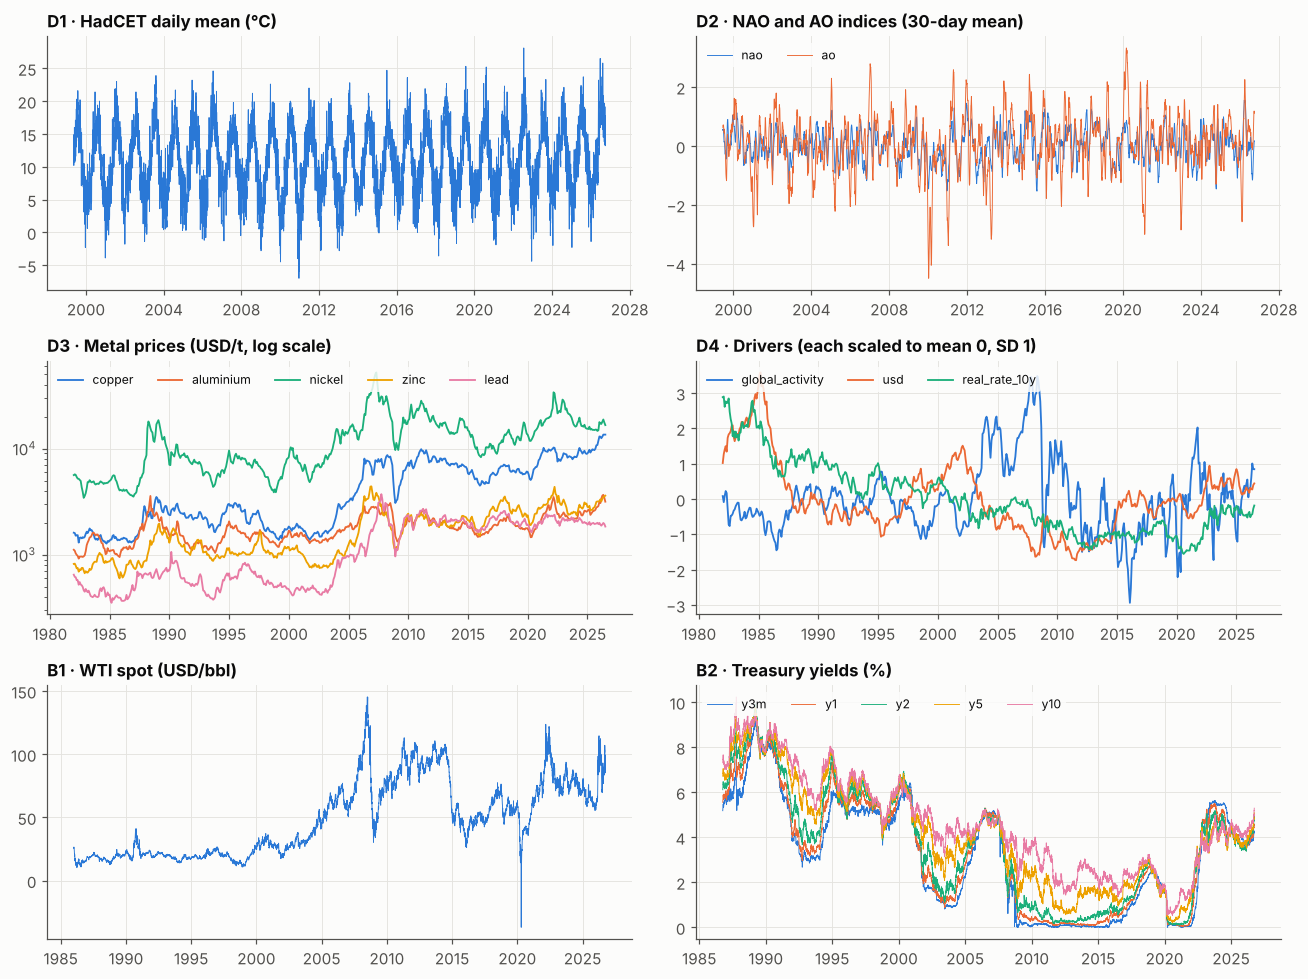

In [24]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
panels = [("D1 · HadCET daily mean (°C)", d1[["temp"]]), ("D2 · NAO and AO indices (30-day mean)",
          d2[["nao", "ao"]].rolling(30).mean()),
          ("D3 · Metal prices (USD/t, log scale)", d3), ("D4 · Drivers (each scaled to mean 0, SD 1)",
          (d4[list(DRIVERS)] - d4[list(DRIVERS)].mean()) / d4[list(DRIVERS)].std()),
          ("B1 · WTI spot (USD/bbl)", b1), ("B2 · Treasury yields (%)", b2)]
for ax, (title, frame) in zip(axes.ravel(), panels):
    for i, col in enumerate(frame.columns):
        ax.plot(frame.index, frame[col], color=SERIES[i], lw=0.6 if len(frame) > 2000 else 1.2, label=col)
    ax.set_title(title, loc="left")
    if frame.shape[1] > 1:
        ax.legend(ncol=min(5, frame.shape[1]), fontsize=8, loc="upper left")
axes[1, 0].set_yscale("log")
fig.tight_layout()
fig.savefig(RESULTS / "figures" / "fig_ch03_00_datasets_overview.png", dpi=150)
plt.show()

## Step 12 · Compare a rebuilt snapshot with the frozen one

When this notebook writes to `data/rebuild/input_timeseries/`, this cell compares each new dataset with the frozen
snapshot over the dates they share. Differences come from two places: new observations at the end, and revisions
by the publishers (the IMF, the BIS and the Dallas Fed revise recent months, and the Met Office revises the
provisional month).

In [25]:
if OUT != INPUT and (INPUT / "D1.csv").exists():
    rows = []
    for name in datasets:
        old = pd.read_csv(INPUT / f"{name}.csv", index_col=0, parse_dates=True)
        new = datasets[name]
        common = old.index.intersection(new.index)
        cols = [c for c in old.columns if c in new.columns]
        diff = (old.loc[common, cols] - new.loc[common, cols]).abs()
        rows.append({"dataset": name, "frozen_last": old.index[-1].date(), "rebuilt_last": new.index[-1].date(),
                     "common_rows": len(common), "max_abs_diff": float(diff.max().max()),
                     "cells_changed": int((diff > 1e-9).sum().sum())})
    display(pd.DataFrame(rows))
else:
    print("This run wrote the frozen snapshot itself; nothing to compare.")

,dataset,frozen_last,rebuilt_last,common_rows,max_abs_diff,cells_changed
0,D1,2026-09-30,2026-09-30,10000,0.000000e+00,0
1,D2,2026-09-30,2026-09-30,10000,1.776357e-15,0
2,D3,2026-07-01,2026-07-01,535,0.000000e+00,0
3,D4,2026-07-01,2026-07-01,535,0.000000e+00,0
4,B1,2026-09-30,2026-09-30,9513,0.000000e+00,0
5,B2,2026-09-30,2026-09-30,10000,0.000000e+00,0


## Key takeaways

- All six datasets come from their original publishers. The manifest records the vintage cut and a SHA-256
  checksum for every raw file, so anyone can audit or rebuild the snapshot.
- D1 passes six checks, including agreement with the Met Office's separately published monthly file.
- Every covariate has an availability class. Fourier terms and day length are known in the future; the wavelet
  bands, NAO, AO and the three D4 drivers are past-only.
- The wavelet bands use only the past, both by construction (equation 5) and by test (changing the future moves
  no past value). The more common two-sided multiresolution bands would not pass that test.
- Unusual moves are flagged, never removed: the negative WTI price of April 2020 stays in the data.
- D3 and D4 cover exactly the same months, so any difference between their forecasts is due to the covariates.

## References

- Central England Temperature (Step 2): Parker, D. E., Legg, T. P., & Folland, C. K. (1992). A new daily Central England Temperature series, 1772–1991. *International Journal of Climatology*, 12(4), 317–342. [doi:10.1002/joc.3370120402](https://doi.org/10.1002/joc.3370120402)
- HadCET version 2 (Step 2): Legg, T., Packman, S., Caton Harrison, T., & McCarthy, M. (2025). An update to the Central England Temperature series: HadCET v2.1. *Geoscience Data Journal*, 12, e284. [doi:10.1002/gdj3.284](https://doi.org/10.1002/gdj3.284)
- NAO and English winter temperature (Step 3d): Hurrell, J. W. (1995). Decadal trends in the North Atlantic Oscillation: regional temperatures and precipitation. *Science*, 269(5224), 676–679. [doi:10.1126/science.269.5224.676](https://doi.org/10.1126/science.269.5224.676)
- Arctic Oscillation (Step 3d): Thompson, D. W. J., & Wallace, J. M. (1998). The Arctic Oscillation signature in the wintertime geopotential height and temperature fields. *Geophysical Research Letters*, 25(9), 1297–1300. [doi:10.1029/98GL00950](https://doi.org/10.1029/98GL00950)
- Day length, the CBM model (Step 3b): Forsythe, W. C., Rykiel, E. J., Stahl, R. S., Wu, H., & Schoolfield, R. M. (1995). A model comparison for daylength as a function of latitude and day of year. *Ecological Modelling*, 80(1), 87–95. [doi:10.1016/0304-3800(94)00034-F](https://doi.org/10.1016/0304-3800(94)00034-F)
- Fourier terms for seasonality (Step 3a): Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), Section 7.4. OTexts. [otexts.com/fpp3](https://otexts.com/fpp3/useful-predictors.html)
- Wavelets and the Haar MODWT (Step 3c): Percival, D. B., & Walden, A. T. (2000). *Wavelet Methods for Time Series Analysis*, chapter 5. Cambridge University Press. [doi:10.1017/CBO9780511841040](https://doi.org/10.1017/CBO9780511841040)
- Wavelet bands as forecasting inputs (Step 3c), an earlier study by the authors of this book: Sengupta, S., Chakraborty, T., & Singh, S. K. (2025). Forecasting CPI inflation under economic policy and geopolitical uncertainties. *International Journal of Forecasting*, 41(3), 953–981. [doi:10.1016/j.ijforecast.2024.08.005](https://doi.org/10.1016/j.ijforecast.2024.08.005)
- Co-movement of commodity prices (Step 4): Pindyck, R. S., & Rotemberg, J. J. (1990). The excess co-movement of commodity prices. *The Economic Journal*, 100(403), 1173–1189. [doi:10.2307/2233966](https://doi.org/10.2307/2233966)
- Common cycles in metal prices (Step 4): Issler, J. V., Rodrigues, C., & Burjack, R. (2014). Using common features to understand the behavior of metal-commodity prices and forecast them at different horizons. *Journal of International Money and Finance*, 42, 310–335. [doi:10.1016/j.jimonfin.2013.08.017](https://doi.org/10.1016/j.jimonfin.2013.08.017)
- Averaging and autocorrelation of changes (Step 4): Working, H. (1960). Note on the correlation of first differences of averages in a random chain. *Econometrica*, 28(4), 916–918. [doi:10.2307/1907574](https://doi.org/10.2307/1907574)
- Global demand as the common driver (Step 5): Kilian, L. (2009). Not all oil price shocks are alike: disentangling demand and supply shocks in the crude oil market. *American Economic Review*, 99(3), 1053–1069. [doi:10.1257/aer.99.3.1053](https://doi.org/10.1257/aer.99.3.1053)
- The corrected Kilian index (Step 5): Kilian, L. (2019). Measuring global real economic activity: do recent critiques hold up to scrutiny? *Economics Letters*, 178, 106–110. [doi:10.1016/j.econlet.2019.03.001](https://doi.org/10.1016/j.econlet.2019.03.001). Data: [Federal Reserve Bank of Dallas](https://www.dallasfed.org/research/igrea)
- The dollar and interest rates as drivers (Step 5): Akram, Q. F. (2009). Commodity prices, interest rates and the dollar. *Energy Economics*, 31(6), 838–851. [doi:10.1016/j.eneco.2009.05.016](https://doi.org/10.1016/j.eneco.2009.05.016)
- Real interest rates and commodity prices (Step 5): Frankel, J. A. (2008). The effect of monetary policy on real commodity prices. In J. Y. Campbell (Ed.), *Asset Prices and Monetary Policy* (pp. 291–333). University of Chicago Press. [NBER chapter](https://www.nber.org/books-and-chapters/asset-prices-and-monetary-policy/effect-monetary-policy-real-commodity-prices)
- The Cleveland Fed real rate (Step 5): Haubrich, J., Pennacchi, G., & Ritchken, P. (2012). Inflation expectations, real rates, and risk premia: evidence from inflation swaps. *The Review of Financial Studies*, 25(5), 1588–1629. [doi:10.1093/rfs/hhs003](https://doi.org/10.1093/rfs/hhs003)
- Level, slope and curvature of the yield curve (Step 7): Nelson, C. R., & Siegel, A. F. (1987). Parsimonious modeling of yield curves. *The Journal of Business*, 60(4), 473–489. [doi:10.1086/296409](https://doi.org/10.1086/296409)
- Forecasting with yield-curve factors (Step 7): Diebold, F. X., & Li, C. (2006). Forecasting the term structure of government bond yields. *Journal of Econometrics*, 130(2), 337–364. [doi:10.1016/j.jeconom.2005.03.005](https://doi.org/10.1016/j.jeconom.2005.03.005)